# Model Comparison

CRISP-DM phase: Evaluation

This notebook loads the four final models (logistic regression, decision tree, random forest and XGBoost) from the `models` folder, with their settings and thresholds. Nothing is copied by hand and nothing is trained again, except a small baseline model in Section 5.

The order matters:

1. The final model is chosen with cross-validation results only (Section 3), before any test result is shown.
2. Then all four models are scored on the test set (2020 to 2024), each with its own threshold for 80% recall (Section 4).
3. Then we check whether the rain, soil and river features add anything to a very small model (Section 5), compare the models with the same number of warnings (Section 6), look at the curves (Section 7) and at each test year (Section 8).

## 1. Setup and Data Loading

### 1.1 Importing Libraries

In [1]:
import os
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold, cross_val_predict, cross_validate
from sklearn.metrics import confusion_matrix, recall_score, precision_score, f1_score, roc_auc_score, average_precision_score, precision_recall_curve, roc_curve

### 1.2 Loading the Data

In [2]:
#loading the saved training and test sets (pcode as text)
train = pd.read_csv('../data/train.csv', dtype={'pcode': str})
test = pd.read_csv('../data/test.csv', dtype={'pcode': str})

In [3]:
#separating the features (X) from the target (y), the same as in the model notebooks
not_features = ['pcode', 'county', 'year', 'month', 'flood_next_month']
X_train = train.drop(not_features, axis=1)
y_train = train['flood_next_month']
X_test = test.drop(not_features, axis=1)
y_test = test['flood_next_month']
print(X_train.shape, X_test.shape)

(9870, 25) (2820, 25)


In [4]:
#share of flood rows in each set
print(round(y_train.mean(), 3), round(y_test.mean(), 3))

0.089 0.051


In [5]:
#the same 5-fold cross-validation that keeps whole years together
year_cv = GroupKFold(n_splits=5)

### 1.3 Loading the Four Final Models

Each model notebook saved its fitted model with `joblib` and its settings and threshold in a `json` file. We load them here.

In [6]:
#file names and display names of the four models
names = ['logistic_regression', 'decision_tree', 'random_forest', 'xgboost']
labels = ['Logistic regression', 'Decision tree', 'Random forest', 'XGBoost']

In [7]:
#loading the four fitted models and their settings files
models = {}
settings = {}
for name in names:
    models[name] = joblib.load('../models/' + name + '.joblib')
    with open('../models/' + name + '_settings.json') as settings_file:
        settings[name] = json.load(settings_file)
print(list(models.keys()))

['logistic_regression', 'decision_tree', 'random_forest', 'xgboost']


In [8]:
#the best settings of each model
for name in names:
    print(name, settings[name]['best_params'])

logistic_regression {'model__l1_ratio': 0, 'model__class_weight': None, 'model__C': 0.004}
decision_tree {'min_samples_leaf': 130, 'max_depth': 8, 'class_weight': 'balanced', 'ccp_alpha': 0.0001}
random_forest {'min_samples_leaf': 20, 'max_features': 0.3, 'max_depth': 4, 'class_weight': None}
xgboost {'subsample': 1.0, 'scale_pos_weight': 10.19047619047619, 'reg_lambda': 5, 'n_estimators': 400, 'min_child_weight': 50, 'max_depth': 3, 'learning_rate': 0.01, 'colsample_bytree': 1.0}


## 2. What Is Compared

All four models were built in the same way (see the model notebooks):

- The settings were chosen with a randomized search scored with **PR-AUC** on 5 folds that keep whole years together.
- The threshold was chosen for **80% recall** with out-of-fold probabilities, using cross-validation only.
- The test set was used once, with `predict_proba >= threshold`.

Two simple rules are used as baselines: the **persistence baseline** (a flood next month if there is a flood this month) and the **calendar baseline** (a warning for the calendar months whose flood rate in the training years is above the overall rate).

## 3. Choosing the Final Model (Before the Test Set)

The rule is decided here, before any test result is shown: **the final model is the one with the highest mean cross-validation PR-AUC.** PR-AUC measures how well a model ranks the flood months above the others, and the cross-validation is made on training years only. The numbers below are the ones saved by the model notebooks.

In [9]:
#cross-validation pr-auc, threshold and out-of-fold results of each model (from the settings files)
rows = []
for i in range(4):
    s = settings[names[i]]
    rows.append({'model': labels[i], 'cv pr-auc mean': s['cv_pr_auc_mean'], 'cv pr-auc std': s['cv_pr_auc_std'],
                 'threshold': s['threshold'], 'oof recall': s['oof_recall'], 'oof precision': s['oof_precision'],
                 'share flagged': s['share_flagged']})
cv_table = pd.DataFrame(rows)
cv_table.round(3)

,model,cv pr-auc mean,cv pr-auc std,threshold,oof recall,oof precision,share flagged
0,Logistic regression,0.439,0.068,0.125,0.800,0.166,0.430
1,Decision tree,0.398,0.076,0.297,0.805,0.173,0.416
2,Random forest,0.465,0.073,0.064,0.800,0.171,0.419
3,XGBoost,0.476,0.080,0.343,0.800,0.171,0.418


In [10]:
#the final model: the highest mean cv pr-auc
final_index = cv_table['cv pr-auc mean'].idxmax()
final_name = names[final_index]
print(labels[final_index])

XGBoost


In [11]:
#the models from the best to the worst mean cv pr-auc, and the gap between the first two
ranked = cv_table.sort_values('cv pr-auc mean', ascending=False)
print(ranked[['model', 'cv pr-auc mean', 'cv pr-auc std']].round(3))
print(round(ranked['cv pr-auc mean'].iloc[0] - ranked['cv pr-auc mean'].iloc[1], 3))

                 model  cv pr-auc mean  cv pr-auc std
3              XGBoost           0.476          0.080
2        Random forest           0.465          0.073
0  Logistic regression           0.439          0.068
1        Decision tree           0.398          0.076
0.012


#### Observation

The settings files give XGBoost the highest mean cross-validation PR-AUC (0.476), followed by the random forest (0.465), the logistic regression (0.439) and the decision tree (0.398). So by the rule written before the test set, **the final model is XGBoost**. The gap between XGBoost and the random forest is only 0.012, much smaller than the std between the folds (0.080 and 0.073), and the logistic regression is not far behind either, so the first three models are close and with only 5 folds we cannot say that the order of XGBoost and the random forest is reliable. The decision tree is the lowest.

At the 80% recall threshold, each model flags between 0.416 and 0.430 of the training months in the out-of-fold predictions. XGBoost, the random forest and the decision tree are very close (out-of-fold precision 0.171, 0.171 and 0.173), and the logistic regression is at 0.166. The decision tree has an out-of-fold recall of 0.805 and not exactly 0.800, because the tree gives only a few different probabilities.

## 4. Test Results of the Four Models

Each model predicts the test set with its own threshold from cross-validation. The two baselines are shown in the same table. The last two columns split the floods found into **new floods** (the county was not flooding this month) and **continuing floods** (the county is already flooding this month).

In [12]:
#flood probabilities and warnings of each model on the test set, at its own threshold
test_prob = {}
test_pred = {}
for name in names:
    test_prob[name] = models[name].predict_proba(X_test)[:, 1]
    test_pred[name] = (test_prob[name] >= settings[name]['threshold']).astype(int)

In [13]:
#persistence baseline: a flood next month if there is a flood this month
persistence_pred = test['flood_this_month']

In [14]:
#calendar baseline: the flood rate of each calendar month in the training years, and yes/no above the overall rate
month_rate = train.groupby('month')['flood_next_month'].mean()
calendar_prob = test['month'].map(month_rate)
calendar_pred = (calendar_prob > y_train.mean()).astype(int)

In [15]:
#new floods and continuing floods in the test set
new_floods = (y_test == 1) & (test['flood_this_month'] == 0)
continuing_floods = (y_test == 1) & (test['flood_this_month'] == 1)
print(new_floods.sum(), continuing_floods.sum())

76 68


In [16]:
#lists with the name, probability and warnings of the four models and the two baselines
method_names = list(labels) + ['Persistence baseline', 'Calendar baseline']
method_probs = [test_prob[name] for name in names] + [persistence_pred, calendar_prob]
method_preds = [test_pred[name] for name in names] + [persistence_pred, calendar_pred]

In [17]:
#test results of the four models and the two baselines
rows = []
for i in range(6):
    prob = method_probs[i]
    pred = method_preds[i]
    rows.append({'method': method_names[i], 'recall': recall_score(y_test, pred), 'precision': precision_score(y_test, pred),
                 'f1': f1_score(y_test, pred), 'roc-auc': roc_auc_score(y_test, prob), 'pr-auc': average_precision_score(y_test, prob),
                 'warnings': pred.sum(), 'new floods found': ((pred == 1) & new_floods).sum(),
                 'continuing floods found': ((pred == 1) & continuing_floods).sum()})
test_results = pd.DataFrame(rows)
test_results.round(3)

,method,recall,precision,f1,roc-auc,pr-auc,warnings,new floods found,continuing floods found
0,Logistic regression,0.875,0.125,0.219,0.870,0.388,1009,58,68
1,Decision tree,0.938,0.105,0.189,0.828,0.291,1281,67,68
2,Random forest,0.979,0.115,0.206,0.892,0.405,1223,73,68
3,XGBoost,0.979,0.120,0.214,0.904,0.374,1172,73,68
4,Persistence baseline,0.472,0.472,0.472,0.722,0.250,144,0,68
5,Calendar baseline,0.847,0.087,0.157,0.762,0.141,1410,66,56


#### Observation

At their own thresholds the four models find a large part of the test floods: the recall is 0.875 for the logistic regression, 0.938 for the decision tree and 0.979 for both the random forest and XGBoost, against 0.472 for the persistence baseline and 0.847 for the calendar baseline. The price is a low precision (0.105 to 0.125) and many warnings (1009 to 1281). Persistence has a much higher precision (0.472) and F1 (0.472, against 0.189 to 0.219 for the models), because it gives only 144 warnings.

In ROC-AUC, XGBoost is first (0.904), then the random forest (0.892), the logistic regression (0.870) and the decision tree (0.828). In PR-AUC the random forest is first (0.405), then the logistic regression (0.388), XGBoost (0.374) and the decision tree (0.291); persistence (0.250) and the calendar baseline (0.141) are lower. So the test set does not put XGBoost first in every measure: XGBoost and the random forest are very close (recall 0.979 for both, new floods found 73 for both, warnings 1172 and 1223), and the test results do not contradict the choice made with cross-validation, but they do not separate the two either.

All four models find 68 of the 68 continuing floods, which the persistence baseline also finds. The difference is in the new floods (76 in the test set): persistence finds 0, the calendar baseline finds 66, and the models find 58 (logistic regression), 67 (decision tree), 73 (random forest) and 73 (XGBoost). The calendar baseline also needs 1410 warnings.

## 5. Do the Rain, Soil and River Features Add Information?

The models know whether the county flooded this month, the flood rate of the county and the month of the year. Maybe these are enough. To test this, we train a very small baseline: a scaled logistic regression (no class weights) on only four features: `flood_this_month`, `county_flood_rate`, `month_sin` and `month_cos`. Its threshold is chosen in the same way, for 80% out-of-fold recall. If the final model does not do better than this baseline, the rain, soil and river features add nothing.

In [18]:
#the four features of the small baseline and its pipeline (scaling first, then logistic regression with default settings)
simple_features = ['flood_this_month', 'county_flood_rate', 'month_sin', 'month_cos']
simple_model = Pipeline([('scaler', StandardScaler()),
                         ('model', LogisticRegression())])

In [19]:
#pr-auc and roc-auc in each fold for the small baseline
scores_simple = cross_validate(simple_model, X_train[simple_features], y_train, cv=year_cv, groups=train['year'], scoring=['average_precision', 'roc_auc'])
print(scores_simple['test_average_precision'].round(3))
print(scores_simple['test_average_precision'].mean().round(3), scores_simple['test_average_precision'].std().round(3))
print(scores_simple['test_roc_auc'].mean().round(3), scores_simple['test_roc_auc'].std().round(3))

[0.354 0.267 0.339 0.345 0.406]
0.342 0.045
0.793 0.012


In [20]:
#out-of-fold probabilities of the small baseline
oof_prob_simple = cross_val_predict(simple_model, X_train[simple_features], y_train, cv=year_cv, groups=train['year'], method='predict_proba')[:, 1]

In [21]:
#choosing the threshold of the small baseline for 80% recall
precision, recall, thresholds = precision_recall_curve(y_train, oof_prob_simple)
threshold_simple = thresholds[recall[:-1] >= 0.80].max()
oof_pred_simple = (oof_prob_simple >= threshold_simple).astype(int)
print(threshold_simple)
print('recall', round(recall_score(y_train, oof_pred_simple), 3))
print('precision', round(precision_score(y_train, oof_pred_simple), 3))
print('share of months flagged', round(oof_pred_simple.mean(), 3))

0.05327374228273638
recall 0.8
precision 0.159
share of months flagged 0.45


In [22]:
#fitting the small baseline on the full training set and predicting the test set
simple_model.fit(X_train[simple_features], y_train)
prob_simple = simple_model.predict_proba(X_test[simple_features])[:, 1]
pred_simple = (prob_simple >= threshold_simple).astype(int)

In [23]:
#the final model and the small baseline side by side
final_prob = test_prob[final_name]
final_pred = test_pred[final_name]
simple_compare = pd.DataFrame({'model': [labels[final_index], 'Small baseline (4 features)'],
                               'cv pr-auc': [settings[final_name]['cv_pr_auc_mean'], scores_simple['test_average_precision'].mean()],
                               'oof precision': [settings[final_name]['oof_precision'], precision_score(y_train, oof_pred_simple)],
                               'test recall': [recall_score(y_test, final_pred), recall_score(y_test, pred_simple)],
                               'test precision': [precision_score(y_test, final_pred), precision_score(y_test, pred_simple)],
                               'test f1': [f1_score(y_test, final_pred), f1_score(y_test, pred_simple)],
                               'test roc-auc': [roc_auc_score(y_test, final_prob), roc_auc_score(y_test, prob_simple)],
                               'test pr-auc': [average_precision_score(y_test, final_prob), average_precision_score(y_test, prob_simple)],
                               'warnings': [final_pred.sum(), pred_simple.sum()],
                               'new floods found': [((final_pred == 1) & new_floods).sum(), ((pred_simple == 1) & new_floods).sum()]})
simple_compare.round(3)

,model,cv pr-auc,oof precision,test recall,test precision,test f1,test roc-auc,test pr-auc,warnings,new floods found
0,XGBoost,0.476,0.171,0.979,0.120,0.214,0.904,0.374,1172,73
1,Small baseline (4 features),0.342,0.159,0.910,0.109,0.195,0.866,0.371,1202,63


#### Observation

The small baseline with four features has a mean cross-validation PR-AUC of 0.342 (std 0.045) and a mean ROC-AUC of 0.793 (std 0.012). XGBoost has a cross-validation PR-AUC of 0.476, so the rain, soil and river features raise the ranking quality in cross-validation. For 80% out-of-fold recall the small baseline needs a threshold of 0.053, flags 0.45 of the months and has a precision of 0.159, against 0.418 and 0.171 for XGBoost.

On the test set, the small baseline raises 1202 warnings and XGBoost raises 1172, so they can be compared directly. XGBoost has a higher recall (0.979 against 0.910), a higher ROC-AUC (0.904 against 0.866) and finds more new floods (73 against 63). But the two have almost the same test PR-AUC (0.374 and 0.371), and their precision and F1 are close (0.120 and 0.109, 0.214 and 0.195). So the four features alone are already a strong baseline, and the extra features add some information, mostly in finding more of the floods, but not in every measure.

## 6. The Same Number of Warnings

Recall depends on how many warnings a method raises. To compare the models fairly, each one is asked to raise the same number of warnings: the rows with the highest probabilities. We use three numbers: 300, the number of warnings of the final model, and the number of warnings of the calendar baseline. Rows with the same probability cannot be told apart; they are kept in the order of the table, so the numbers for a model with many tied probabilities (like the decision tree) are only a guide.

In [24]:
#the three numbers of warnings to compare
k_values = [300, int(final_pred.sum()), int(calendar_pred.sum())]
print(k_values)

[300, 1172, 1410]


In [25]:
#floods found in the k rows with the highest probability, for the four models and the small baseline
compare_names = list(labels) + ['Small baseline (4 features)']
compare_probs = [test_prob[name] for name in names] + [prob_simple]
rows = []
for i in range(5):
    order = np.argsort(-compare_probs[i], kind='stable')
    ranked_floods = y_test.values[order]
    row = {'model': compare_names[i]}
    for k in k_values:
        row['floods found with ' + str(k) + ' warnings'] = ranked_floods[:k].sum()
    rows.append(row)
same_warnings = pd.DataFrame(rows)
same_warnings

,model,floods found with 300 warnings,floods found with 1172 warnings,floods found with 1410 warnings
0,Logistic regression,78,133,138
1,Decision tree,68,135,135
2,Random forest,77,139,143
3,XGBoost,79,141,142
4,Small baseline (4 features),82,131,136


In [26]:
#floods found by the calendar baseline with its own warnings
print(calendar_pred.sum(), ((calendar_pred == 1) & (y_test == 1)).sum())

1410 122


#### Observation

With 300 warnings, the models find between 68 and 82 of the 144 floods, and the small baseline is the best (82), ahead of XGBoost (79) and the logistic regression (78), so for the highest-ranked months the four features alone are at least as good as the full model. With the same number of warnings as XGBoost (1172), XGBoost finds 141 floods, the random forest 139, the decision tree 135, the logistic regression 133 and the small baseline 131. With the number of warnings of the calendar baseline (1410), the random forest finds 143, XGBoost 142, the logistic regression 138, the small baseline 136 and the decision tree 135, while the calendar baseline itself finds 122. So with the same number of warnings, every model finds more floods than the calendar baseline, and XGBoost and the random forest are the best two and very close. The decision tree gives only a few different probabilities, so its numbers depend on the order of the tied rows and are only a guide.

## 7. ROC and Precision-Recall Curves

The curves show how each model ranks the test months at all the possible thresholds. The dashed line is a model with no skill.

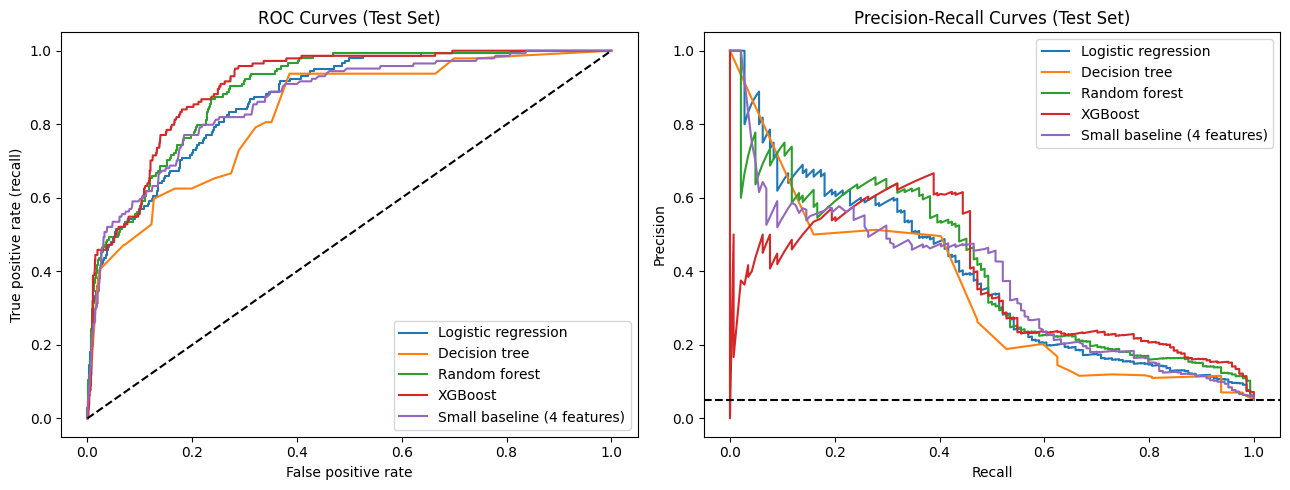

In [27]:
#roc curves (left) and precision-recall curves (right) of the four models and the small baseline
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for i in range(5):
    fpr, tpr, roc_thresholds = roc_curve(y_test, compare_probs[i])
    axes[0].plot(fpr, tpr, label=compare_names[i])
    prec, rec, pr_thresholds = precision_recall_curve(y_test, compare_probs[i])
    axes[1].plot(rec, prec, label=compare_names[i])
axes[0].plot([0, 1], [0, 1], 'k--')
axes[0].set_xlabel('False positive rate')
axes[0].set_ylabel('True positive rate (recall)')
axes[0].set_title('ROC Curves (Test Set)')
axes[0].legend()
axes[1].axhline(y_test.mean(), color='k', linestyle='--')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].set_title('Precision-Recall Curves (Test Set)')
axes[1].legend()
plt.tight_layout()
plt.show()

#### Observation

In the ROC curves, all the models are far above the dashed line of a model with no skill. XGBoost and the random forest are on top for most of the curve, the decision tree is lowest and its curve is made of a few long steps (it gives few different probabilities), and the logistic regression and the small baseline are close to each other in between. In the precision-recall curves, all the models are above the dashed line at 0.051 (the share of floods in the test set). The curves are close together and jump up and down on the left, where only a few months are flagged. For high recall, the precision of every model falls to low values, which agrees with the precision of 0.105 to 0.125 in Section 4.

## 8. Test Results Year by Year

The recall on the test set is higher than the 80% we aimed for in cross-validation. To see where this comes from, we look at the final model year by year. First the test years, then the training years with their out-of-fold predictions (each year predicted by a model that did not see it).

In [28]:
#floods, floods found and warnings of the final model in each test year
rows = []
for year in sorted(test['year'].unique()):
    in_year = (test['year'] == year)
    floods = ((y_test == 1) & in_year).sum()
    found = ((final_pred == 1) & (y_test == 1) & in_year).sum()
    warnings_year = ((final_pred == 1) & in_year).sum()
    rows.append({'year': year, 'floods': floods, 'floods found': found, 'warnings': warnings_year,
                 'share of months flagged': warnings_year / in_year.sum(), 'recall': found / floods,
                 'new floods': (new_floods & in_year).sum(), 'new floods found': ((final_pred == 1) & new_floods & in_year).sum()})
test_years = pd.DataFrame(rows)
test_years.round(3)

,year,floods,floods found,warnings,share of months flagged,recall,new floods,new floods found
0,2020,39,37,271,0.480,0.949,14,12
1,2021,30,30,247,0.438,1.000,16,16
2,2022,3,3,94,0.167,1.000,3,3
3,2023,31,30,338,0.599,0.968,28,27
4,2024,41,41,222,0.394,1.000,15,15


In [29]:
#out-of-fold probabilities and warnings of the final model for the training years
oof_final = cross_val_predict(models[final_name], X_train, y_train, cv=year_cv, groups=train['year'], method='predict_proba')[:, 1]
oof_final_pred = (oof_final >= settings[final_name]['threshold']).astype(int)

In [30]:
#floods, floods found and warnings of the final model in each training year (out-of-fold)
rows = []
for year in sorted(train['year'].unique()):
    in_year = (train['year'] == year)
    floods = ((y_train == 1) & in_year).sum()
    found = ((oof_final_pred == 1) & (y_train == 1) & in_year).sum()
    warnings_year = ((oof_final_pred == 1) & in_year).sum()
    rows.append({'year': year, 'floods': floods, 'floods found': found, 'warnings': warnings_year,
                 'share of months flagged': warnings_year / in_year.sum(), 'recall': found / floods})
train_years = pd.DataFrame(rows)
train_years.round(3)

,year,floods,floods found,warnings,share of months flagged,recall
0,2002,14,8,122,0.433,0.571
1,2003,48,44,253,0.449,0.917
2,2004,29,25,143,0.254,0.862
3,2005,14,11,109,0.193,0.786
4,2006,75,60,242,0.429,0.800
5,2007,104,90,289,0.512,0.865
6,2008,47,34,264,0.468,0.723
7,2009,73,41,193,0.342,0.562
8,2010,78,59,230,0.408,0.756
9,2011,73,65,325,0.576,0.890


In [31]:
#how many years have a recall below 0.80, in the training years (out-of-fold) and in the test years
print(len(train_years), (train_years['recall'] < 0.80).sum(), train_years['recall'].min().round(3), train_years['recall'].max().round(3))
print(len(test_years), (test_years['recall'] < 0.80).sum(), test_years['recall'].min().round(3), test_years['recall'].max().round(3))

18 9 0.562 1.0
5 0 0.949 1.0


In [32]:
#share of months flagged in the training years (out-of-fold) and in the test set
print(round(oof_final_pred.mean(), 3), round(final_pred.mean(), 3))

0.418 0.416


#### Observation

On the test set, the final model finds 37 of 39 floods in 2020 (recall 0.949), 30 of 30 in 2021, 3 of 3 in 2022, 30 of 31 in 2023 (0.968) and 41 of 41 in 2024. No test year has a recall below 0.80. The new floods are found in the same way (73 of 76 in total, with the missed ones in 2020 and 2023). 2022 has only 3 floods, so it weighs little.

In the out-of-fold predictions of the training years, the recall of the final model goes from 0.562 (2009) to 1.0 (2016, 2018 and 2019), and 9 of the 18 years are below 0.80. So the 0.80 from cross-validation is an average over years with very different results, and all 5 test years are in the upper part of that range. The final model flags about the same share of the months in the test set (0.416) as in the out-of-fold predictions (0.418), so its higher recall does not come from more warnings, and the share changes a lot from year to year (from 0.167 in 2022 to 0.599 in 2023 in the test years). The tables do not say why the test years are easier. Five years are not many, so the test recall is a result for these five years, and the cross-validation recall of 0.80 is the more careful number to plan with.

## 9. Confusion Matrices of the Final Model

The confusion matrix of the final model at its threshold, for the out-of-fold predictions of the training years (cross-validation, left) and for the test set (right). Each row is the true outcome and each column is the prediction.

In [33]:
#confusion matrices of the final model: out-of-fold (training years) and test set
cm_cv = confusion_matrix(y_train, oof_final_pred)
cm_test = confusion_matrix(y_test, final_pred)
print(cm_cv)
print(cm_test)

[[5565 3423]
 [ 176  706]]
[[1645 1031]
 [   3  141]]


In [34]:
#floods found, missed, false alarms and warnings in cross-validation and on the test set
cm_table = pd.DataFrame({'set': ['Cross-validation (out-of-fold)', 'Test set'],
                         'floods': [cm_cv[1, 0] + cm_cv[1, 1], cm_test[1, 0] + cm_test[1, 1]],
                         'floods found': [cm_cv[1, 1], cm_test[1, 1]],
                         'floods missed': [cm_cv[1, 0], cm_test[1, 0]],
                         'false alarms': [cm_cv[0, 1], cm_test[0, 1]],
                         'warnings': [cm_cv[0, 1] + cm_cv[1, 1], cm_test[0, 1] + cm_test[1, 1]]})
cm_table

,set,floods,floods found,floods missed,false alarms,warnings
0,Cross-validation (out-of-fold),882,706,176,3423,4129
1,Test set,144,141,3,1031,1172


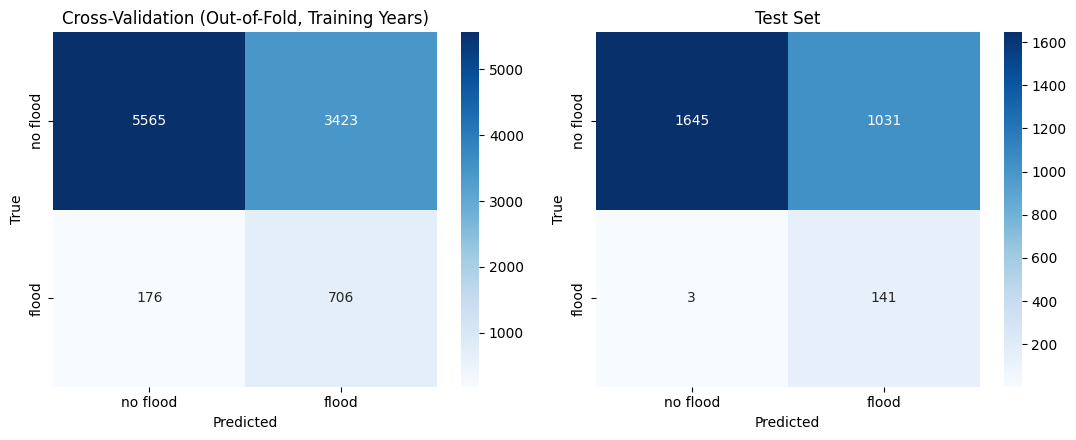

In [35]:
#the two confusion matrices side by side
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
sns.heatmap(cm_cv, annot=True, fmt='d', cmap='Blues', xticklabels=['no flood', 'flood'], yticklabels=['no flood', 'flood'], ax=axes[0])
axes[0].set_title('Cross-Validation (Out-of-Fold, Training Years)')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('True')
sns.heatmap(cm_test, annot=True, fmt='d', cmap='Blues', xticklabels=['no flood', 'flood'], yticklabels=['no flood', 'flood'], ax=axes[1])
axes[1].set_title('Test Set')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('True')
plt.tight_layout()
plt.show()

#### Observation

For the final XGBoost model at its threshold of 0.343, the out-of-fold matrix (882 floods in the training years) shows 706 floods found, 176 missed, 3423 false alarms and 4129 warnings. The test matrix (144 floods) shows 141 floods found, 3 missed, 1031 false alarms and 1172 warnings. In both sets the false alarms are much more numerous than the floods found, so most warnings are false alarms. The model finds 706 of 882 floods in cross-validation and 141 of 144 on the test set, which agrees with the recalls of 0.800 and 0.979 in the earlier tables. The numbers of warnings are 4129 and 1172, which are 0.418 and 0.416 of the months, almost the same share in both sets.

## 10. Cross-Validation and Test Results Together

The recall, precision and share of months flagged of each model in cross-validation (out-of-fold, training years) and on the test set, at the same threshold.

In [36]:
#out-of-fold results and test results of each model at its threshold
rows = []
for i in range(4):
    s = settings[names[i]]
    pred = test_pred[names[i]]
    rows.append({'model': labels[i], 'oof recall': s['oof_recall'], 'test recall': recall_score(y_test, pred),
                 'oof precision': s['oof_precision'], 'test precision': precision_score(y_test, pred),
                 'oof share flagged': s['share_flagged'], 'test share flagged': pred.mean()})
cv_vs_test = pd.DataFrame(rows)
cv_vs_test.round(3)

,model,oof recall,test recall,oof precision,test precision,oof share flagged,test share flagged
0,Logistic regression,0.800,0.875,0.166,0.125,0.430,0.358
1,Decision tree,0.805,0.938,0.173,0.105,0.416,0.454
2,Random forest,0.800,0.979,0.171,0.115,0.419,0.434
3,XGBoost,0.800,0.979,0.171,0.120,0.418,0.416


#### Observation

For all four models the test recall (0.875, 0.938, 0.979 and 0.979) is higher than the out-of-fold recall (0.800, 0.805, 0.800 and 0.800). The test precision (0.125, 0.105, 0.115 and 0.120) is lower than the out-of-fold precision (0.166, 0.173, 0.171 and 0.171). Floods are rarer in the test set (a share of 0.051 against 0.089 in the training set, printed in Section 1.2), which makes a high precision harder. The share of months flagged is higher on the test set for the decision tree (0.454 against 0.416), the random forest (0.434 against 0.419) while for XGBoost it is the same (0.416 against 0.418), and lower for the logistic regression (0.358 against 0.430), whose test recall is still higher (0.875 against 0.800). So the higher recall on the test set does not only come from more warnings: XGBoost has the same share flagged and a recall of 0.979 against 0.800.

## 11. The Final Model

**The final model is XGBoost.** It was chosen in Section 3 by the highest mean cross-validation PR-AUC (0.476), before the test results were shown, and the choice was not changed afterwards.

- **Settings:** `max_depth` = 3, `n_estimators` = 400, `learning_rate` = 0.01, `subsample` = 1.0, `colsample_bytree` = 1.0, `min_child_weight` = 50, `reg_lambda` = 5 and `scale_pos_weight` = 10.19. The best `learning_rate` and `min_child_weight` are still at the edge of their lists (smallest and largest value tried), so better values may exist outside the lists.
- **Threshold:** 0.343, chosen for 80% out-of-fold recall (out-of-fold precision 0.171, 0.418 of the months flagged).
- **Test set:** recall 0.979, precision 0.120, F1 0.214, ROC-AUC 0.904 and PR-AUC 0.374, with 1172 warnings in 2820 months. It finds 73 of the 76 new floods and 68 of the 68 continuing floods.

**The random forest is a close second.** Its cross-validation PR-AUC is 0.465, a gap of 0.012 that is within the year-to-year std (0.073 and 0.080). On the test set the random forest has a higher PR-AUC (0.405 against 0.374), while the recall (0.979 for both) and the new floods found (73 for both) are the same, and XGBoost has a higher ROC-AUC (0.904 against 0.892) and gives fewer warnings (1172 against 1223). We do not claim that XGBoost is clearly better than the random forest. We keep XGBoost because the rule was fixed before the test set, and the test set does not contradict it. The random forest would also be a reasonable choice.

**What the models add:**

- Compared with persistence, the models find far more floods (recall 0.979 against 0.472), mainly the new floods that persistence cannot find, but with a much lower precision (0.120 against 0.472).
- Compared with the small four-feature baseline, XGBoost has a higher cross-validation PR-AUC (0.476 against 0.342), a higher recall and ROC-AUC on the test set and finds more new floods (73 against 63), but the test PR-AUC is almost the same (0.374 and 0.371). So the rain, soil and river features add some information, but the gain is moderate.
- The test recall (0.979) is higher than the 0.80 of cross-validation, with the same share of months flagged (0.416 against 0.418). The year-by-year tables show that all 5 test years have a recall of 0.949 or more, while 9 of the 18 training years are below 0.80 in cross-validation. The cross-validation figure is the more careful one to plan with.

## 12. Summary of the Model Comparison

- **Method:** four models were tuned with `RandomizedSearchCV` scored with PR-AUC on year folds, and each got a threshold for 80% out-of-fold recall. The models, settings and thresholds were loaded from the `models` folder. The final model was chosen by the highest mean cross-validation PR-AUC before looking at the test set.
- **Cross-validation (mean PR-AUC, std between folds):** XGBoost 0.476 (0.080), random forest 0.465 (0.073), logistic regression 0.439 (0.068), decision tree 0.398 (0.076).
- **Final model:** XGBoost, threshold 0.343. The random forest is a close second (the gap of 0.012 is within the std).
- **Test results (threshold for 80% recall from cross-validation):**

| Method | Recall | Precision | F1 | ROC-AUC | PR-AUC | Warnings | New floods found (of 76) | Continuing floods found (of 68) |
|---|---|---|---|---|---|---|---|---|
| Logistic regression | 0.875 | 0.125 | 0.219 | 0.870 | 0.388 | 1009 | 58 | 68 |
| Decision tree | 0.938 | 0.105 | 0.189 | 0.828 | 0.291 | 1281 | 67 | 68 |
| Random forest | 0.979 | 0.115 | 0.206 | 0.892 | 0.405 | 1223 | 73 | 68 |
| XGBoost (final) | 0.979 | 0.120 | 0.214 | 0.904 | 0.374 | 1172 | 73 | 68 |
| Persistence baseline | 0.472 | 0.472 | 0.472 | 0.722 | 0.250 | 144 | 0 | 68 |
| Calendar baseline | 0.847 | 0.087 | 0.157 | 0.762 | 0.141 | 1410 | 66 | 56 |

- **Small four-feature baseline:** cross-validation PR-AUC 0.342, test recall 0.910, ROC-AUC 0.866, PR-AUC 0.371 and 63 new floods found with 1202 warnings. XGBoost is better in cross-validation, recall, ROC-AUC and new floods found, and almost equal in test PR-AUC (0.374 against 0.371).
- **Same number of warnings:** with 1172 warnings XGBoost finds 141 floods; with 1410 warnings the random forest finds 143 and XGBoost 142, against 122 for the calendar baseline.
- **Test years:** the recall of the final model is 0.949 or more in each of the 5 test years, while 9 of the 18 training years are below 0.80 in cross-validation. The cross-validation recall of 0.80 is the more careful number to plan with.
- **Limits that stay:** (1) the folds hold out whole years but train on years before and after them, so cross-validation is not a pure forecast of the future; (2) `county_flood_rate` is calculated from all the training years, so the cross-validation scores are slightly optimistic; (3) the data stops in December 2024 (no 2025 data was added); (4) the test set has only 144 floods in 5 years, and 3 of them are in 2022.
- **Feature selection:** the 24 features were chosen in the EDA notebooks using only the training rows (July 2002 to December 2019), so the test years were not used to choose them.